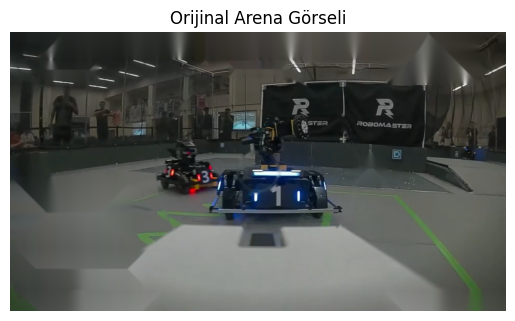

In [1]:
import cv2
import numpy as np
import urllib.request
from matplotlib import pyplot as plt

url = "https://i.imgur.com/rLOD58k.png"

req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})

response = urllib.request.urlopen(req)
arr = np.asarray(bytearray(response.read()), dtype=np.uint8)

img_bgr = cv2.imdecode(arr, -1)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)

plt.imshow(img_rgb)
plt.title('Orijinal Arena Görseli')
plt.axis('off')
plt.show()

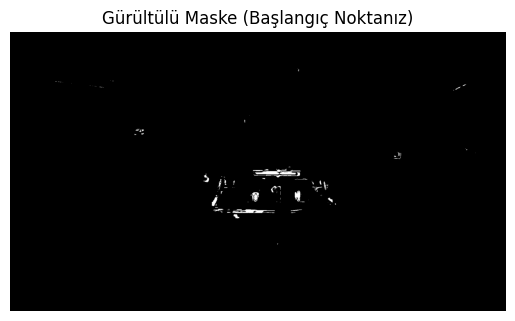

In [2]:
import cv2
import numpy as np
import urllib.request
from matplotlib import pyplot as plt

url = "https://i.imgur.com/rLOD58k.png"

req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})

response = urllib.request.urlopen(req)
arr = np.asarray(bytearray(response.read()), dtype=np.uint8)

img_bgr = cv2.imdecode(arr, -1)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)

lower_blue = np.array([100, 40, 120])
upper_blue = np.array([140, 255, 255])
mask_blue = cv2.inRange(img_hsv, lower_blue, upper_blue)

lower_white = np.array([0, 0, 240])
upper_white = np.array([179, 30, 255])
mask_white = cv2.inRange(img_hsv, lower_white, upper_white)

noisy_mask = cv2.bitwise_or(mask_blue, mask_white)

plt.imshow(noisy_mask, cmap='gray')
plt.title('Gürültülü Maske (Başlangıç ​​Noktanız)')
plt.axis('off')
plt.show()

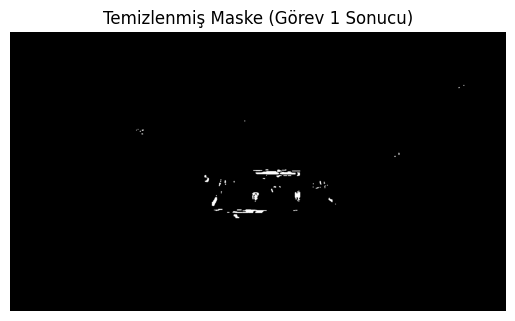

In [8]:
# ==========================================
# GÖREV 1: MORFOLOJİ İLE GÜRÜLTÜ TEMİZLEME
# ==========================================

kernel = np.ones((3,3),dtype=np.uint8)

eroded_mask = cv2.erode(noisy_mask, kernel, iterations=1)

cleaned_mask = cv2.dilate(eroded_mask, kernel, iterations=1)

# (Not: OpenCV'de, aşındırma ve ardından genişletmeyi birleştirme, Morfolojik Açma olarak
# bilinen standart bir işlemdir ve ana şekli korurken istenmeyen gürültüyü temizler.)

plt.imshow(cleaned_mask, cmap='gray')
plt.title('Temizlenmiş Maske (Görev 1 Sonucu)')
plt.axis('off')
plt.show()

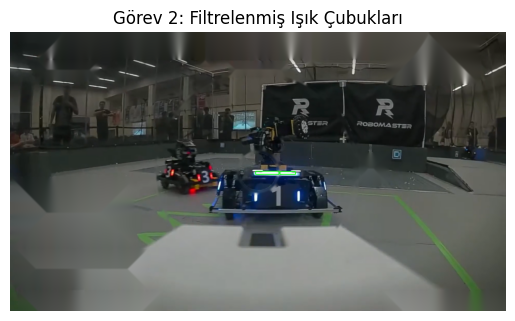

In [9]:
# ==========================================
# GÖREV 2: KONTÜR VE GEOMETRİK FİLTRELEME
# ==========================================

output_img = img_rgb.copy()

contours, hierarchy = cv2.findContours(
    cleaned_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

for cnt in contours:
    rect = cv2.minAreaRect(cnt)

    (center_x, center_y), (width, height), angle = rect

    if width == 0 or height == 0:
        continue

    min_side = min(width, height)
    max_side = max(width, height)

    aspect_ratio = min_side / max_side

    if aspect_ratio < 0.25 and 50 < max_side < 110:
        box = cv2.boxPoints(rect)
        box = np.int32(box)

        cv2.drawContours(output_img, [box], 0, (0, 255, 0), 2)

plt.imshow(output_img)
plt.title('Görev 2: Filtrelenmiş Işık Çubukları')
plt.axis('off')
plt.show()